# Sales Performance and Business Intelligence Analysis

## End-to-End Data Analytics Project

**Scope:** Data Analytics only  
**Excluded:** Machine Learning, predictive modeling, forecasting models, model training, and model evaluation.

### Analytical workflow
1. Business understanding
2. Data loading and understanding
3. Data quality assessment
4. Data cleaning
5. Feature engineering
6. KPI analysis
7. Exploratory Data Analysis
8. Sales trend analysis
9. Product analysis
10. Customer analysis
11. Regional analysis
12. Shipping and operational analysis
13. Outlier and distribution analysis
14. Business insights and recommendations

**Dataset file required:** `sales_forcasting.csv`


## 1. Import Required Libraries

We import only the libraries required for data analytics, statistical exploration, and visualization.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

sns.set_theme(style="whitegrid")


## 2. Load the Dataset

We load the CSV file and inspect the first records to understand the structure of the data.

In [3]:
FILE_PATH = "sales_forcasting.csv"

df = pd.read_csv(FILE_PATH)

print(f"Dataset loaded successfully.")
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]:,}")

display(df.head())


Dataset loaded successfully.
Rows: 9,800
Columns: 18


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,"42,420.00",South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,"42,420.00",South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,"90,036.00",West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,"33,311.00",South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.58
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,"33,311.00",South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.37


## 3. Data Structure and Column Overview

We inspect column names and data types before beginning analysis. This is important because date fields must be converted to datetime before time-based analysis.

In [4]:
display(pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Non-Null Count": df.notna().sum().values,
    "Missing Count": df.isna().sum().values
}))


,Column,Data Type,Non-Null Count,Missing Count
0,Row ID,int64,9800,0
1,Order ID,object,9800,0
2,Order Date,object,9800,0
3,Ship Date,object,9800,0
4,Ship Mode,object,9800,0
5,Customer ID,object,9800,0
6,Customer Name,object,9800,0
7,Segment,object,9800,0
8,Country,object,9800,0
9,City,object,9800,0


## 4. Statistical Summary

We examine numerical distributions using count, mean, standard deviation, minimum, quartiles, and maximum.

In [5]:
display(df.describe(include="all").T)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Row ID,"9,800.00",NaN,NaN,NaN,"4,900.50","2,829.16",1.00,"2,450.75","4,900.50","7,350.25","9,800.00"
Order ID,9800,4922,CA-2018-100111,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order Date,9800,1230,05/09/2017,38,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship Date,9800,1326,26/09/2018,34,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship Mode,9800,4,Standard Class,5859,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer ID,9800,793,WB-21850,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Name,9800,793,William Brown,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Segment,9800,3,Consumer,5101,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,9800,1,United States,9800,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,9800,529,New York City,891,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 5. Data Quality Assessment

### 5.1 Missing Values

We calculate both the number and percentage of missing values. Missing values are assessed based on business importance rather than automatically deleting rows.

In [6]:
missing_summary = pd.DataFrame({
    "Missing Values": df.isna().sum(),
    "Missing Percentage": (df.isna().mean() * 100).round(2)
}).sort_values("Missing Values", ascending=False)

display(missing_summary[missing_summary["Missing Values"] > 0])


,Missing Values,Missing Percentage
Postal Code,11,0.11


### 5.2 Duplicate Records

We check for completely duplicated rows. Duplicate transactions can incorrectly inflate revenue and order metrics.

In [7]:
duplicate_count = df.duplicated().sum()
print(f"Duplicate rows: {duplicate_count:,}")


Duplicate rows: 0


### 5.3 Date Conversion

We convert order and ship dates to datetime format. This enables yearly, quarterly, monthly, and shipping-duration analysis.

In [8]:
date_columns = ["Order Date", "Ship Date"]

for col in date_columns:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors="coerce", dayfirst=True)

display(df[date_columns].head())
print(df[date_columns].dtypes)


,Order Date,Ship Date
0,2017-11-08,2017-11-11
1,2017-11-08,2017-11-11
2,2017-06-12,2017-06-16
3,2016-10-11,2016-10-18
4,2016-10-11,2016-10-18


Order Date    datetime64[ns]
Ship Date     datetime64[ns]
dtype: object


### 5.4 Missing Value Treatment

Postal Code is not required for the core revenue analysis. We preserve transactions and label missing postal codes as `Unknown` where appropriate.

In [9]:
if "Postal Code" in df.columns:
    df["Postal Code"] = df["Postal Code"].fillna("Unknown")

print("Missing values after treatment:")
display(df.isna().sum()[df.isna().sum() > 0])


Missing values after treatment:


Series([], dtype: int64)

## 6. Feature Engineering

We create analytical fields from the existing transaction data.

These fields support:
- time-series analysis,
- seasonal analysis,
- quarterly comparison,
- shipping-duration analysis.

In [10]:
df["Year"] = df["Order Date"].dt.year
df["Month Number"] = df["Order Date"].dt.month
df["Month Name"] = df["Order Date"].dt.month_name()
df["Quarter"] = "Q" + df["Order Date"].dt.quarter.astype(str)
df["Year-Month"] = df["Order Date"].dt.to_period("M").astype(str)
df["Day Name"] = df["Order Date"].dt.day_name()

if {"Order Date", "Ship Date"}.issubset(df.columns):
    df["Shipping Days"] = (df["Ship Date"] - df["Order Date"]).dt.days

display(df.head())


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Year,Month Number,Month Name,Quarter,Year-Month,Day Name,Shipping Days
0,1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,"42,420.00",South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2017,11,November,Q4,2017-11,Wednesday,3
1,2,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,"42,420.00",South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,2017,11,November,Q4,2017-11,Wednesday,3
2,3,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,"90,036.00",West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2017,6,June,Q2,2017-06,Monday,4
3,4,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,"33,311.00",South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.58,2016,10,October,Q4,2016-10,Tuesday,7
4,5,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,"33,311.00",South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.37,2016,10,October,Q4,2016-10,Tuesday,7


## 7. Business KPI Analysis

We calculate the core performance indicators used by management.

In [11]:
total_sales = df["Sales"].sum()
total_orders = df["Order ID"].nunique() if "Order ID" in df.columns else len(df)
total_customers = df["Customer ID"].nunique() if "Customer ID" in df.columns else np.nan
total_products = df["Product ID"].nunique() if "Product ID" in df.columns else np.nan
average_order_value = total_sales / total_orders

kpis = {
    "Total Sales": total_sales,
    "Total Orders": total_orders,
    "Total Customers": total_customers,
    "Total Products": total_products,
    "Average Order Value": average_order_value
}

if "Shipping Days" in df.columns:
    kpis["Average Shipping Days"] = df["Shipping Days"].mean()

kpi_table = pd.DataFrame(
    {"Metric": list(kpis.keys()), "Value": list(kpis.values())}
)

display(kpi_table)


,Metric,Value
0,Total Sales,"2,261,536.78"
1,Total Orders,"4,922.00"
2,Total Customers,793.00
3,Total Products,"1,861.00"
4,Average Order Value,459.48
5,Average Shipping Days,3.96


## 8. Annual Sales Trend

We aggregate sales by year to identify long-term business growth or decline.

In [12]:
yearly_sales = (
    df.groupby("Year", as_index=False)["Sales"]
      .sum()
      .sort_values("Year")
)

yearly_sales["YoY Growth %"] = yearly_sales["Sales"].pct_change() * 100

display(yearly_sales)


,Year,Sales,YoY Growth %
0,2015,"479,856.21",NaN
1,2016,"459,436.01",-4.26
2,2017,"600,192.55",30.64
3,2018,"722,052.02",20.30


### Graph: Annual Sales Trend

A line chart is used because the objective is to show change over time.

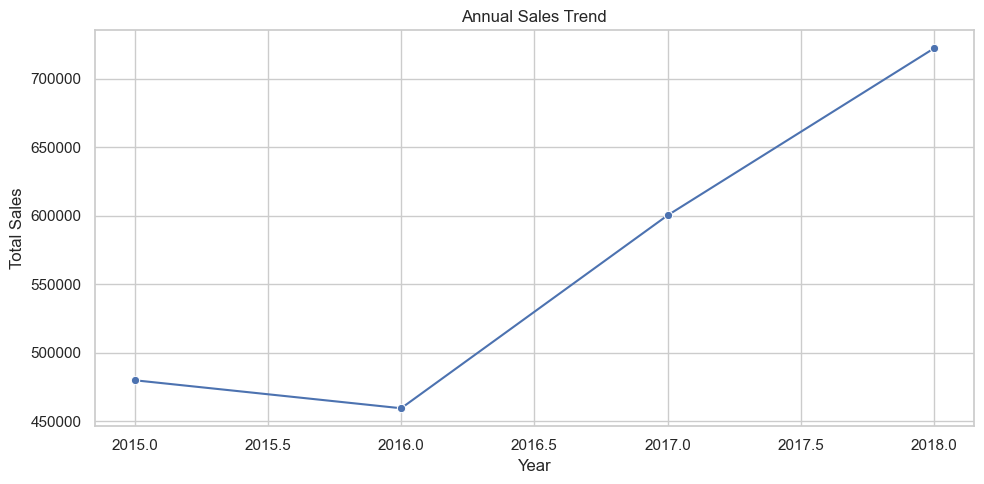

In [13]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=yearly_sales,
    x="Year",
    y="Sales",
    marker="o"
)

plt.title("Annual Sales Trend")
plt.xlabel("Year")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()


### Insight

The annual table and graph should be interpreted together:

- Positive YoY growth indicates expansion.
- Negative YoY growth indicates a decline requiring investigation.
- The highest-sales year represents the strongest annual performance.

The following code identifies the strongest and weakest years dynamically.

In [14]:
best_year = yearly_sales.loc[yearly_sales["Sales"].idxmax()]
worst_year = yearly_sales.loc[yearly_sales["Sales"].idxmin()]

print(f"Best sales year: {int(best_year['Year'])} with sales of {best_year['Sales']:,.2f}")
print(f"Lowest sales year: {int(worst_year['Year'])} with sales of {worst_year['Sales']:,.2f}")

growth_table = yearly_sales.dropna(subset=["YoY Growth %"])
if not growth_table.empty:
    highest_growth = growth_table.loc[growth_table["YoY Growth %"].idxmax()]
    lowest_growth = growth_table.loc[growth_table["YoY Growth %"].idxmin()]
    print(f"Highest YoY growth: {int(highest_growth['Year'])} ({highest_growth['YoY Growth %']:.2f}%)")
    print(f"Lowest YoY growth: {int(lowest_growth['Year'])} ({lowest_growth['YoY Growth %']:.2f}%)")


Best sales year: 2018 with sales of 722,052.02
Lowest sales year: 2016 with sales of 459,436.01
Highest YoY growth: 2017 (30.64%)
Lowest YoY growth: 2016 (-4.26%)


## 9. Monthly Sales Analysis

We aggregate sales by calendar month to identify recurring seasonal patterns.

In [15]:
monthly_sales = (
    df.groupby(["Month Number", "Month Name"], as_index=False)["Sales"]
      .sum()
      .sort_values("Month Number")
)

display(monthly_sales)


,Month Number,Month Name,Sales
0,1,January,"94,291.63"
1,2,February,"59,371.12"
2,3,March,"197,573.59"
3,4,April,"136,283.00"
4,5,May,"154,086.72"
5,6,June,"145,837.52"
6,7,July,"145,535.69"
7,8,August,"157,315.93"
8,9,September,"300,103.41"
9,10,October,"199,496.29"


### Graph: Monthly Sales Trend

A line chart is appropriate because the months have a natural chronological sequence.

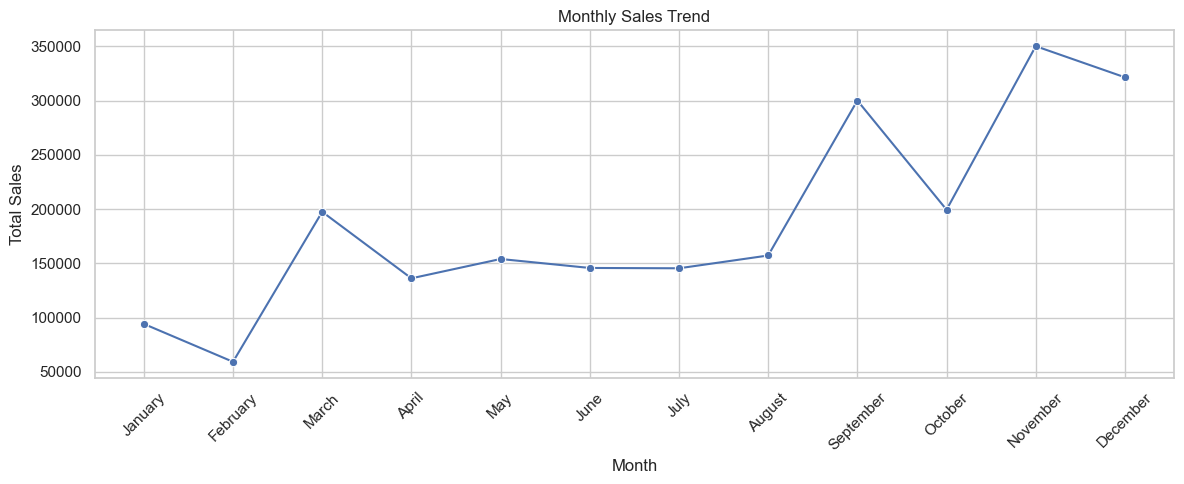

In [16]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_sales,
    x="Month Name",
    y="Sales",
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### Insight

In [17]:
best_month = monthly_sales.loc[monthly_sales["Sales"].idxmax()]
lowest_month = monthly_sales.loc[monthly_sales["Sales"].idxmin()]

print(f"Highest-sales month: {best_month['Month Name']} ({best_month['Sales']:,.2f})")
print(f"Lowest-sales month: {lowest_month['Month Name']} ({lowest_month['Sales']:,.2f})")


Highest-sales month: November (350,161.71)
Lowest-sales month: February (59,371.12)


## 10. Quarterly Sales Analysis

Quarterly analysis helps management compare broad business periods and identify the strongest quarter.

In [18]:
quarterly_sales = (
    df.groupby(["Year", "Quarter"], as_index=False)["Sales"]
      .sum()
)

quarter_summary = (
    quarterly_sales.groupby("Quarter", as_index=False)["Sales"]
    .sum()
    .sort_values("Sales", ascending=False)
)

display(quarter_summary)


,Quarter,Sales
3,Q4,"871,138.18"
2,Q3,"602,955.03"
1,Q2,"436,207.25"
0,Q1,"351,236.33"


### Graph: Sales by Quarter

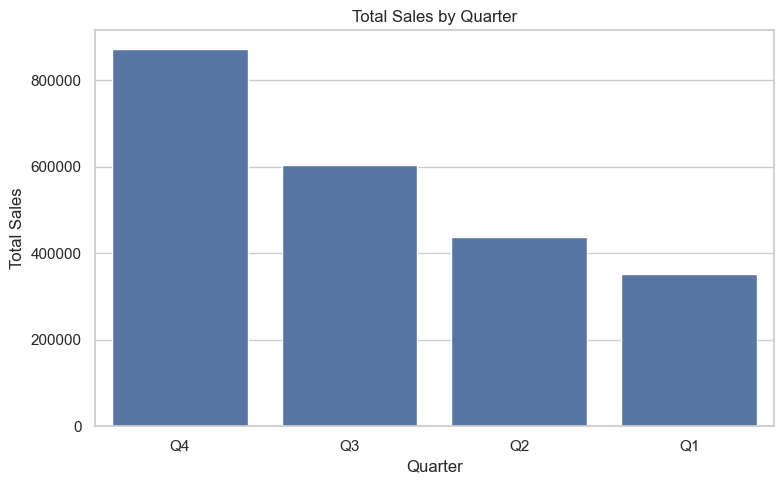

In [19]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=quarter_summary,
    x="Quarter",
    y="Sales",
    order=quarter_summary["Quarter"]
)

plt.title("Total Sales by Quarter")
plt.xlabel("Quarter")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()


### Insight

In [20]:
best_quarter = quarter_summary.iloc[0]
print(f"Strongest quarter: {best_quarter['Quarter']} with sales of {best_quarter['Sales']:,.2f}")


Strongest quarter: Q4 with sales of 871,138.18


## 11. Monthly Sales Heatmap

A year-month heatmap allows us to compare seasonal patterns across different years.

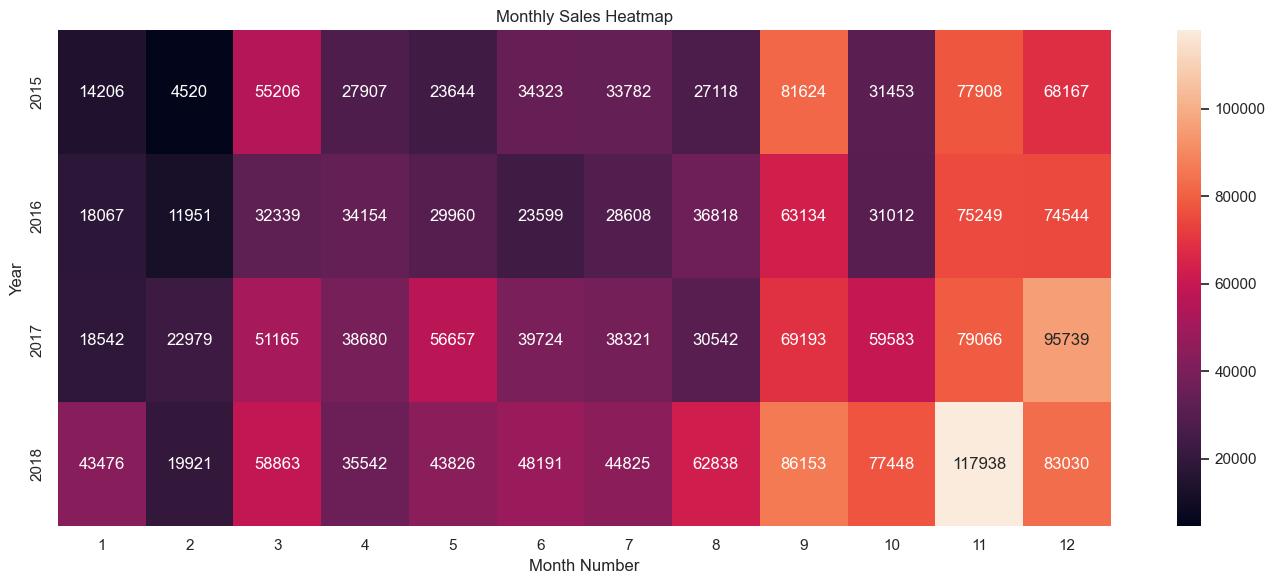

In [21]:
monthly_heatmap = pd.pivot_table(
    df,
    values="Sales",
    index="Year",
    columns="Month Number",
    aggfunc="sum"
)

plt.figure(figsize=(14, 6))

sns.heatmap(
    monthly_heatmap,
    annot=True,
    fmt=".0f"
)

plt.title("Monthly Sales Heatmap")
plt.xlabel("Month Number")
plt.ylabel("Year")
plt.tight_layout()
plt.show()


## 12. Category Analysis

We compare revenue contribution across major product categories.

In [22]:
category_sales = (
    df.groupby("Category", as_index=False)["Sales"]
      .sum()
      .sort_values("Sales", ascending=False)
)

category_sales["Revenue Share %"] = (
    category_sales["Sales"] / category_sales["Sales"].sum() * 100
)

display(category_sales)


,Category,Sales,Revenue Share %
2,Technology,"827,455.87",36.59
0,Furniture,"728,658.58",32.22
1,Office Supplies,"705,422.33",31.19


### Graph: Sales by Category

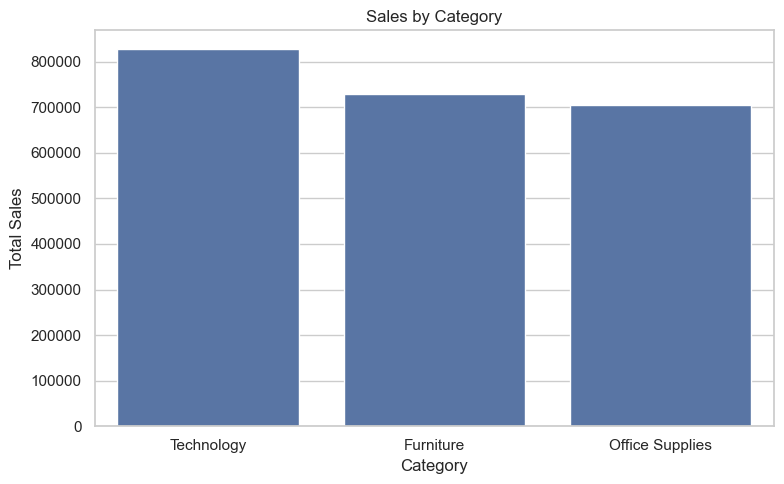

In [23]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=category_sales,
    x="Category",
    y="Sales",
    order=category_sales["Category"]
)

plt.title("Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()


### Insight

In [24]:
top_category = category_sales.iloc[0]
print(f"Leading category: {top_category['Category']}")
print(f"Revenue contribution: {top_category['Revenue Share %']:.2f}%")


Leading category: Technology
Revenue contribution: 36.59%


## 13. Sub-Category Analysis

Sub-category analysis provides a more granular view of product performance.

In [25]:
subcategory_sales = (
    df.groupby("Sub-Category", as_index=False)["Sales"]
      .sum()
      .sort_values("Sales", ascending=False)
)

display(subcategory_sales.head(10))


,Sub-Category,Sales
13,Phones,"327,782.45"
5,Chairs,"322,822.73"
14,Storage,"219,343.39"
16,Tables,"202,810.63"
3,Binders,"200,028.79"
11,Machines,"189,238.63"
0,Accessories,"164,186.70"
6,Copiers,"146,248.09"
4,Bookcases,"113,813.20"
1,Appliances,"104,618.40"


### Graph: Top 10 Sub-Categories

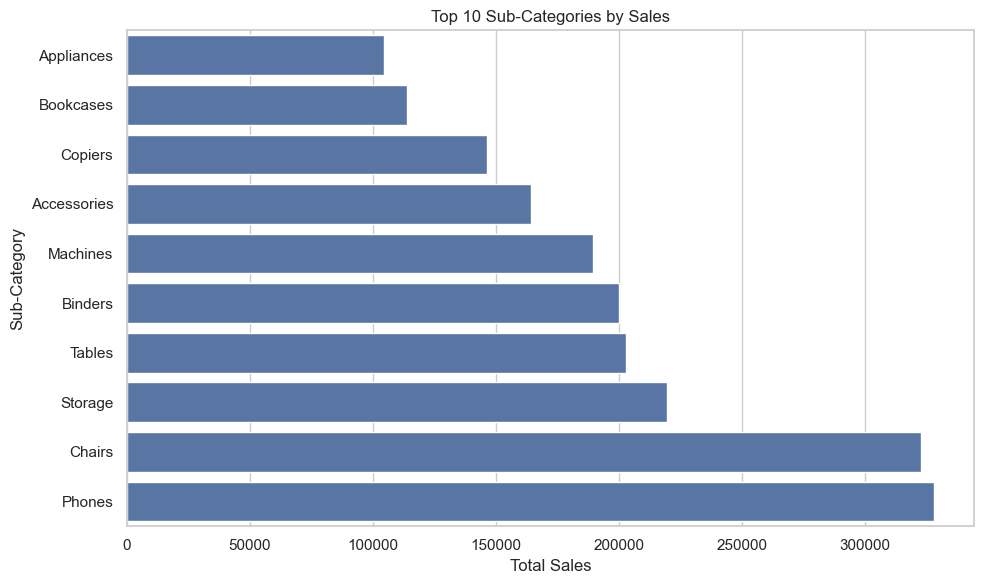

In [26]:
top_subcategories = subcategory_sales.head(10).sort_values("Sales")

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_subcategories,
    x="Sales",
    y="Sub-Category"
)

plt.title("Top 10 Sub-Categories by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Sub-Category")
plt.tight_layout()
plt.show()


### Insight

In [27]:
top_subcategory = subcategory_sales.iloc[0]
print(f"Top sub-category: {top_subcategory['Sub-Category']}")
print(f"Sales: {top_subcategory['Sales']:,.2f}")


Top sub-category: Phones
Sales: 327,782.45


## 14. Customer Segment Analysis

We analyze how much revenue each customer segment contributes.

In [28]:
segment_sales = (
    df.groupby("Segment", as_index=False)["Sales"]
      .sum()
      .sort_values("Sales", ascending=False)
)

segment_sales["Revenue Share %"] = (
    segment_sales["Sales"] / segment_sales["Sales"].sum() * 100
)

display(segment_sales)


,Segment,Sales,Revenue Share %
0,Consumer,"1,148,060.53",50.76
1,Corporate,"688,494.07",30.44
2,Home Office,"424,982.18",18.79


### Graph: Sales by Customer Segment

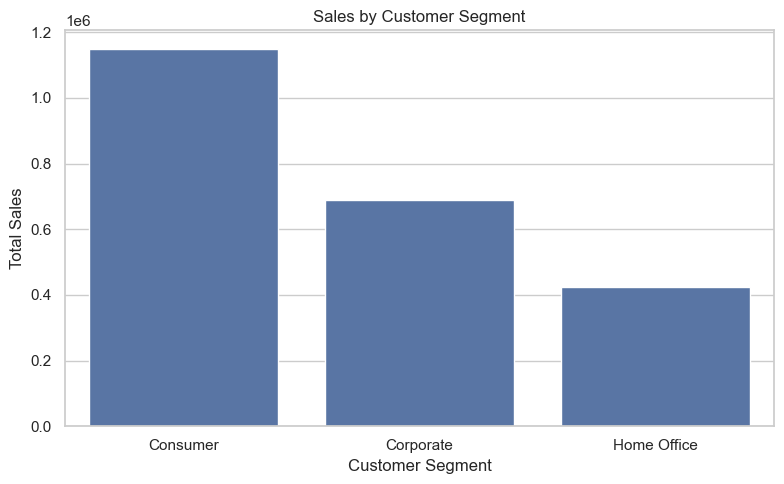

In [29]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=segment_sales,
    x="Segment",
    y="Sales",
    order=segment_sales["Segment"]
)

plt.title("Sales by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()


### Insight

In [30]:
top_segment = segment_sales.iloc[0]
print(f"Highest-revenue customer segment: {top_segment['Segment']}")
print(f"Revenue contribution: {top_segment['Revenue Share %']:.2f}%")


Highest-revenue customer segment: Consumer
Revenue contribution: 50.76%


## 15. Regional Sales Analysis

We compare performance across regions.

In [31]:
region_sales = (
    df.groupby("Region", as_index=False)["Sales"]
      .sum()
      .sort_values("Sales", ascending=False)
)

region_sales["Revenue Share %"] = (
    region_sales["Sales"] / region_sales["Sales"].sum() * 100
)

display(region_sales)


,Region,Sales,Revenue Share %
3,West,"710,219.68",31.40
1,East,"669,518.73",29.60
0,Central,"492,646.91",21.78
2,South,"389,151.46",17.21


### Graph: Sales by Region

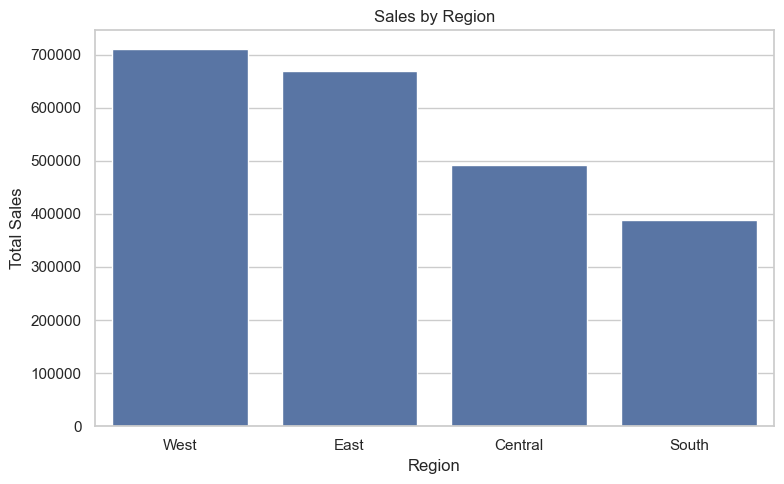

In [32]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=region_sales,
    x="Region",
    y="Sales",
    order=region_sales["Region"]
)

plt.title("Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()


### Insight

In [33]:
top_region = region_sales.iloc[0]
lowest_region = region_sales.iloc[-1]

print(f"Top-performing region: {top_region['Region']} ({top_region['Sales']:,.2f})")
print(f"Lowest-performing region: {lowest_region['Region']} ({lowest_region['Sales']:,.2f})")


Top-performing region: West (710,219.68)
Lowest-performing region: South (389,151.46)


## 16. Region × Category Analysis

This analysis determines whether category performance differs across regions.

In [34]:
region_category_sales = pd.pivot_table(
    df,
    values="Sales",
    index="Region",
    columns="Category",
    aggfunc="sum",
    fill_value=0
)

display(region_category_sales)


Category,Furniture,Office Supplies,Technology
Region,,,
Central,"160,317.46","163,590.24","168,739.21"
East,"206,461.39","199,940.81","263,116.53"
South,"116,531.48","124,424.77","148,195.21"
West,"245,348.25","217,466.51","247,404.93"


### Graph: Region and Category Comparison

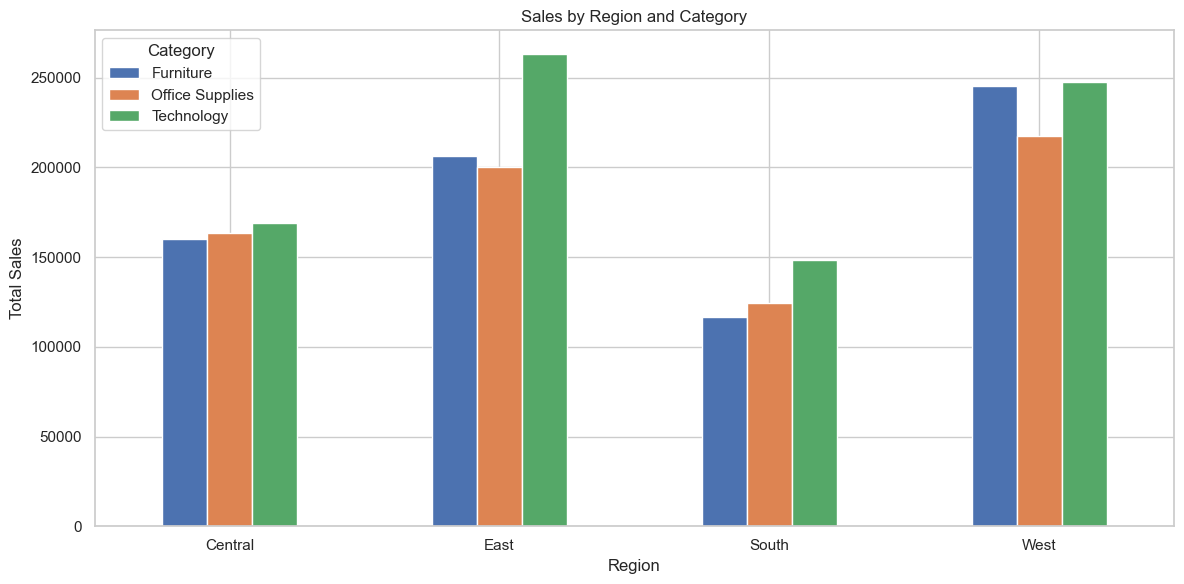

In [35]:
region_category_sales.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Sales by Region and Category")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 17. State-Level Analysis

State-level analysis helps identify geographically strong and weak markets.

In [36]:
state_sales = (
    df.groupby("State", as_index=False)["Sales"]
      .sum()
      .sort_values("Sales", ascending=False)
)

display(state_sales.head(10))


,State,Sales
3,California,"446,306.46"
30,New York,"306,361.15"
41,Texas,"168,572.53"
45,Washington,"135,206.85"
36,Pennsylvania,"116,276.65"
8,Florida,"88,436.53"
11,Illinois,"79,236.52"
20,Michigan,"76,136.07"
33,Ohio,"75,130.35"
44,Virginia,"70,636.72"


### Graph: Top 10 States by Sales

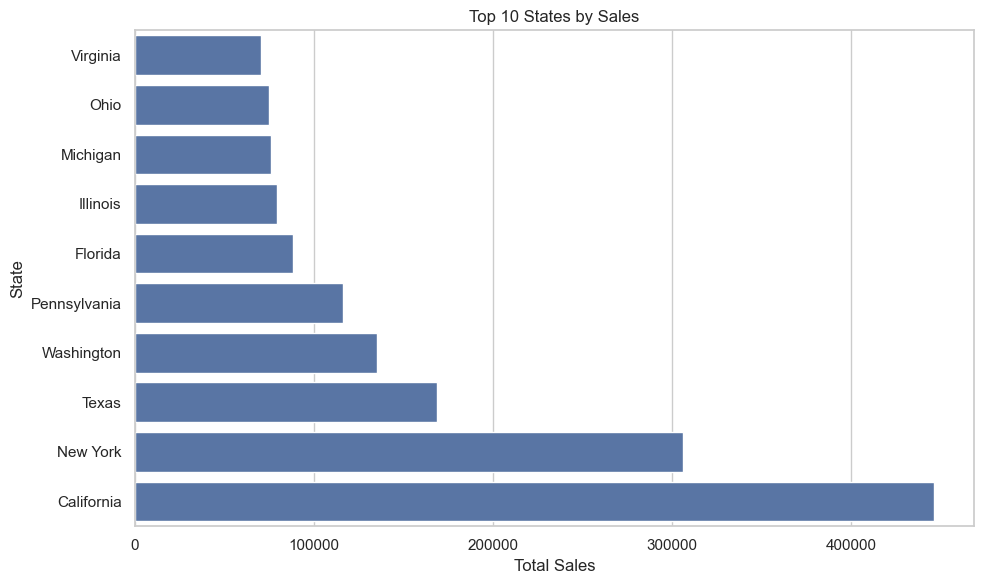

In [37]:
top_states = state_sales.head(10).sort_values("Sales")

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_states,
    x="Sales",
    y="State"
)

plt.title("Top 10 States by Sales")
plt.xlabel("Total Sales")
plt.ylabel("State")
plt.tight_layout()
plt.show()


## 18. Customer Revenue Analysis

We calculate the total revenue generated by each customer.

In [38]:
customer_sales = (
    df.groupby(["Customer ID", "Customer Name"], as_index=False)["Sales"]
      .sum()
      .sort_values("Sales", ascending=False)
)

display(customer_sales.head(10))


,Customer ID,Customer Name,Sales
700,SM-20320,Sean Miller,"25,043.05"
741,TC-20980,Tamara Chand,"19,052.22"
621,RB-19360,Raymond Buch,"15,117.34"
730,TA-21385,Tom Ashbrook,"14,595.62"
6,AB-10105,Adrian Barton,"14,473.57"
434,KL-16645,Ken Lonsdale,"14,175.23"
669,SC-20095,Sanjit Chand,"14,142.33"
327,HL-15040,Hunter Lopez,"12,873.30"
683,SE-20110,Sanjit Engle,"12,209.44"
131,CC-12370,Christopher Conant,"12,129.07"


### Graph: Top 10 Customers by Revenue

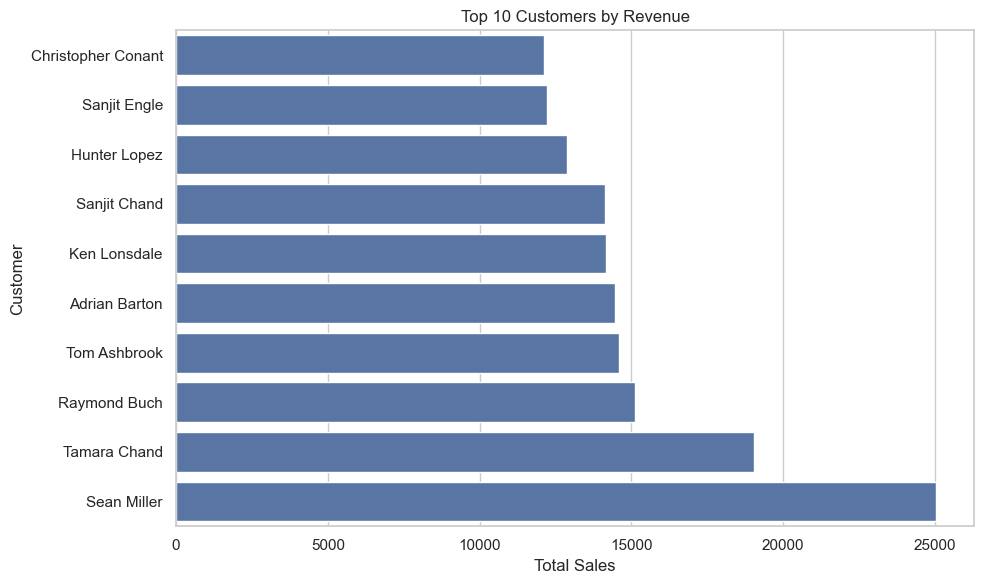

In [39]:
top_customers = customer_sales.head(10).sort_values("Sales")

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_customers,
    x="Sales",
    y="Customer Name"
)

plt.title("Top 10 Customers by Revenue")
plt.xlabel("Total Sales")
plt.ylabel("Customer")
plt.tight_layout()
plt.show()


## 19. Customer Order Frequency

Revenue alone does not show purchasing behavior. We also calculate how frequently customers place orders.

In [40]:
customer_frequency = (
    df.groupby(["Customer ID", "Customer Name"], as_index=False)
      .agg(
          Total_Orders=("Order ID", "nunique"),
          Total_Sales=("Sales", "sum")
      )
      .sort_values("Total_Orders", ascending=False)
)

display(customer_frequency.head(10))


,Customer ID,Customer Name,Total_Orders,Total_Sales
275,EP-13915,Emily Phan,17,"5,478.06"
791,ZC-21910,Zuschuss Carroll,13,"8,025.71"
147,CK-12205,Chloris Kastensmidt,13,"3,154.86"
356,JE-15745,Joel Eaton,13,"6,760.82"
591,PG-18820,Patrick Gardner,13,"3,086.91"
691,SH-19975,Sally Hughsby,12,"2,465.66"
653,RP-19390,Resi Pölking,12,"5,153.08"
694,SJ-20125,Sanjit Jacobs,12,"3,949.66"
99,BP-11095,Bart Pistole,12,"2,442.04"
576,NS-18640,Noel Staavos,12,"2,857.75"


## 20. RFM Customer Analysis

RFM is a descriptive customer analytics method.

- **Recency:** days since the customer's latest purchase
- **Frequency:** number of distinct orders
- **Monetary:** total revenue generated

This analysis supports customer prioritization without using machine learning.

In [41]:
analysis_date = df["Order Date"].max()

rfm = (
    df.groupby(["Customer ID", "Customer Name"])
      .agg(
          Recency=("Order Date", lambda x: (analysis_date - x.max()).days),
          Frequency=("Order ID", "nunique"),
          Monetary=("Sales", "sum")
      )
      .reset_index()
)

display(rfm.head())


,Customer ID,Customer Name,Recency,Frequency,Monetary
0,AA-10315,Alex Avila,184,5,"5,563.56"
1,AA-10375,Allen Armold,19,9,"1,056.39"
2,AA-10480,Andrew Allen,259,4,"1,790.51"
3,AA-10645,Anna Andreadi,55,6,"5,086.93"
4,AB-10015,Aaron Bergman,415,3,886.16


### RFM Distribution

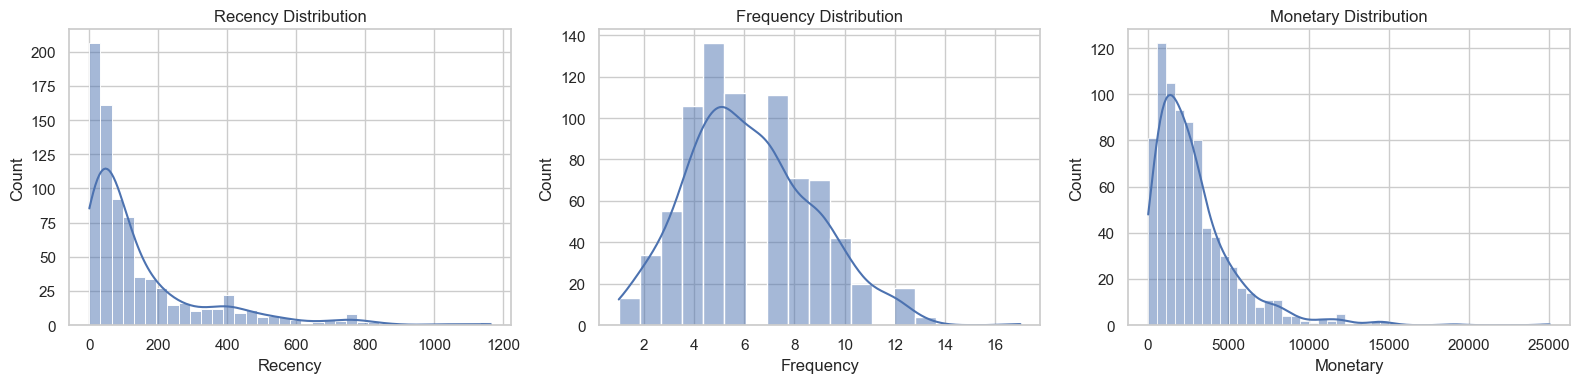

In [42]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(rfm["Recency"], kde=True, ax=axes[0])
axes[0].set_title("Recency Distribution")

sns.histplot(rfm["Frequency"], kde=True, ax=axes[1])
axes[1].set_title("Frequency Distribution")

sns.histplot(rfm["Monetary"], kde=True, ax=axes[2])
axes[2].set_title("Monetary Distribution")

plt.tight_layout()
plt.show()


## 21. Product Performance Analysis

We identify the products generating the most revenue.

In [43]:
product_sales = (
    df.groupby(["Product ID", "Product Name"], as_index=False)["Sales"]
      .sum()
      .sort_values("Sales", ascending=False)
)

display(product_sales.head(10))


,Product ID,Product Name,Sales
1639,TEC-CO-10004722,Canon imageCLASS 2200 Advanced Copier,"61,599.82"
787,OFF-BI-10003527,Fellowes PB500 Electric Punch Plastic Comb Bin...,"27,453.38"
1668,TEC-MA-10002412,Cisco TelePresence System EX90 Videoconferenci...,"22,638.48"
82,FUR-CH-10002024,HON 5400 Series Task Chairs for Big and Tall,"21,870.58"
701,OFF-BI-10001359,GBC DocuBind TL300 Electric Binding System,"19,823.48"
667,OFF-BI-10000545,GBC Ibimaster 500 Manual ProClick Binding System,"19,024.50"
1629,TEC-CO-10001449,Hewlett Packard LaserJet 3310 Copier,"18,839.69"
1656,TEC-MA-10001127,HP Designjet T520 Inkjet Large Format Printer ...,"18,374.90"
858,OFF-BI-10004995,GBC DocuBind P400 Electric Binding System,"17,965.07"
1442,OFF-SU-10000151,High Speed Automatic Electric Letter Opener,"17,030.31"


### Graph: Top 10 Products

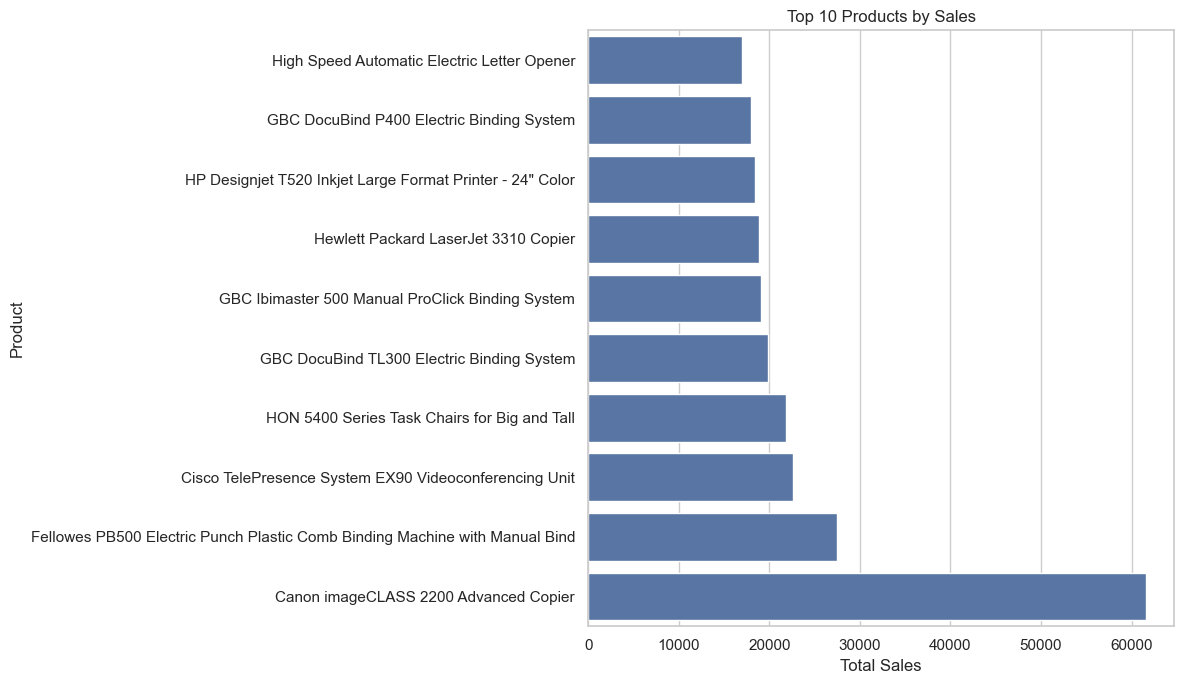

In [44]:
top_products = product_sales.head(10).sort_values("Sales")

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_products,
    x="Sales",
    y="Product Name"
)

plt.title("Top 10 Products by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product")
plt.tight_layout()
plt.show()


## 22. Pareto Product Analysis

We identify how much of total revenue is generated by the highest-selling products.

The analysis follows the 80/20 principle as an analytical question, not as an assumption.

In [45]:
product_revenue = (
    df.groupby("Product Name")["Sales"]
      .sum()
      .sort_values(ascending=False)
)

pareto = product_revenue.reset_index()
pareto["Cumulative Sales"] = pareto["Sales"].cumsum()
pareto["Cumulative Revenue %"] = (
    pareto["Cumulative Sales"] / pareto["Sales"].sum() * 100
)

display(pareto.head(10))


,Product Name,Sales,Cumulative Sales,Cumulative Revenue %
0,Canon imageCLASS 2200 Advanced Copier,"61,599.82","61,599.82",2.72
1,Fellowes PB500 Electric Punch Plastic Comb Bin...,"27,453.38","89,053.21",3.94
2,Cisco TelePresence System EX90 Videoconferenci...,"22,638.48","111,691.69",4.94
3,HON 5400 Series Task Chairs for Big and Tall,"21,870.58","133,562.26",5.91
4,GBC DocuBind TL300 Electric Binding System,"19,823.48","153,385.74",6.78
5,GBC Ibimaster 500 Manual ProClick Binding System,"19,024.50","172,410.24",7.62
6,Hewlett Packard LaserJet 3310 Copier,"18,839.69","191,249.93",8.46
7,HP Designjet T520 Inkjet Large Format Printer ...,"18,374.90","209,624.82",9.27
8,GBC DocuBind P400 Electric Binding System,"17,965.07","227,589.89",10.06
9,High Speed Automatic Electric Letter Opener,"17,030.31","244,620.20",10.82


### Graph: Product Pareto Analysis

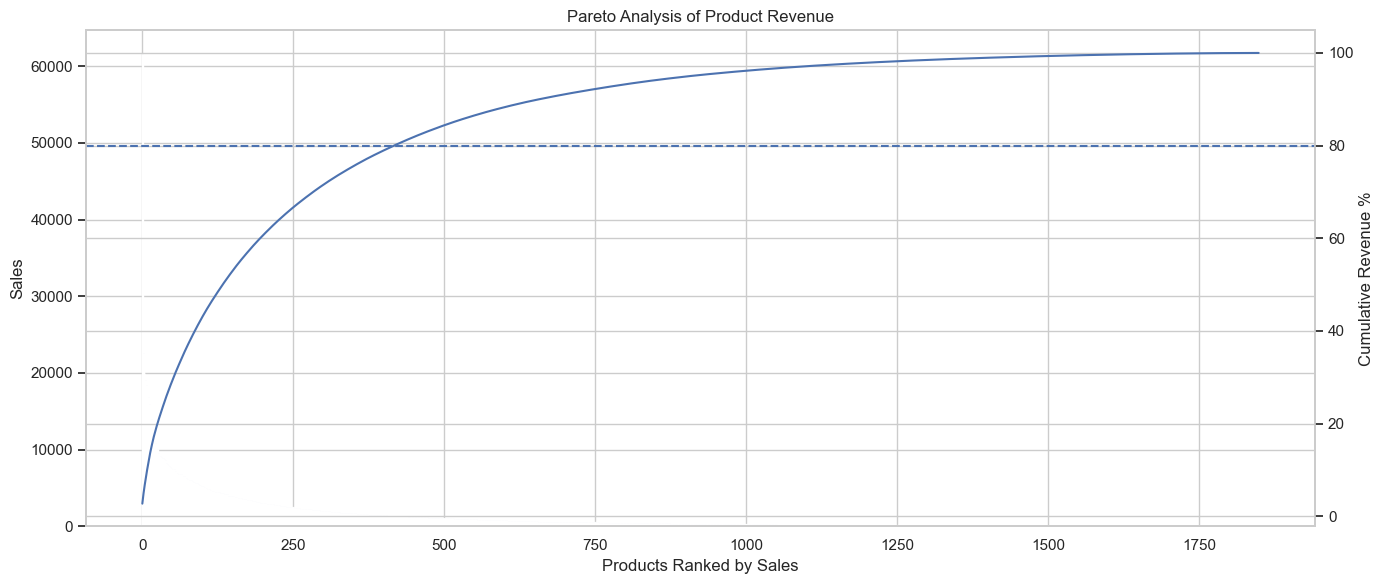

In [46]:
fig, ax1 = plt.subplots(figsize=(14, 6))

x = np.arange(len(pareto))

ax1.bar(x, pareto["Sales"])
ax1.set_xlabel("Products Ranked by Sales")
ax1.set_ylabel("Sales")

ax2 = ax1.twinx()
ax2.plot(x, pareto["Cumulative Revenue %"])
ax2.axhline(80, linestyle="--")
ax2.set_ylabel("Cumulative Revenue %")

plt.title("Pareto Analysis of Product Revenue")
plt.tight_layout()
plt.show()


## 23. Sales Distribution and Outlier Analysis

We inspect the distribution of individual transactions. High-value transactions should not automatically be deleted because they may represent genuine bulk or enterprise purchases.

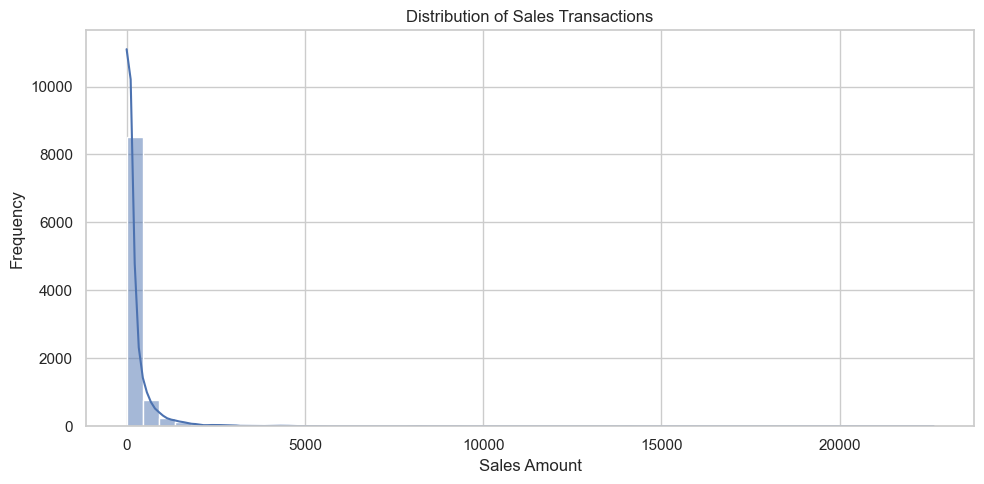

In [47]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["Sales"],
    bins=50,
    kde=True
)

plt.title("Distribution of Sales Transactions")
plt.xlabel("Sales Amount")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


### Boxplot Analysis

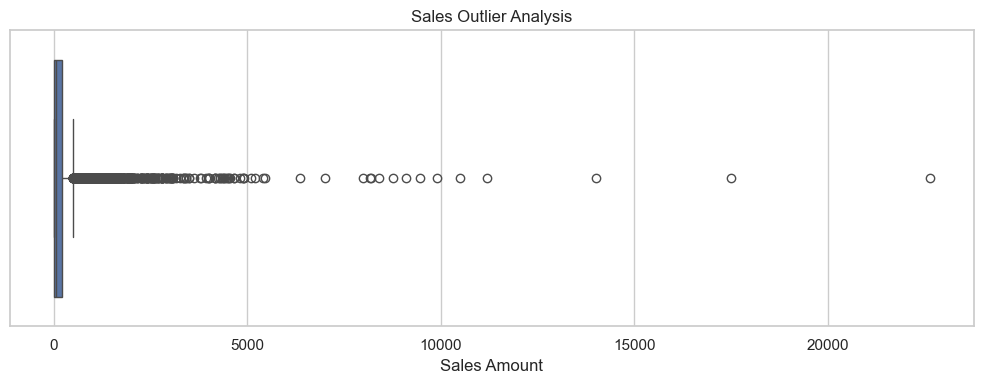

In [48]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=df["Sales"])

plt.title("Sales Outlier Analysis")
plt.xlabel("Sales Amount")
plt.tight_layout()
plt.show()


## 24. Shipping Mode Analysis

We analyze the distribution of shipping methods.

In [49]:
shipping_mode_sales = (
    df.groupby("Ship Mode", as_index=False)["Sales"]
      .sum()
      .sort_values("Sales", ascending=False)
)

display(shipping_mode_sales)


,Ship Mode,Sales
3,Standard Class,"1,340,831.31"
2,Second Class,"449,914.18"
0,First Class,"345,572.26"
1,Same Day,"125,219.04"


### Graph: Sales by Shipping Mode

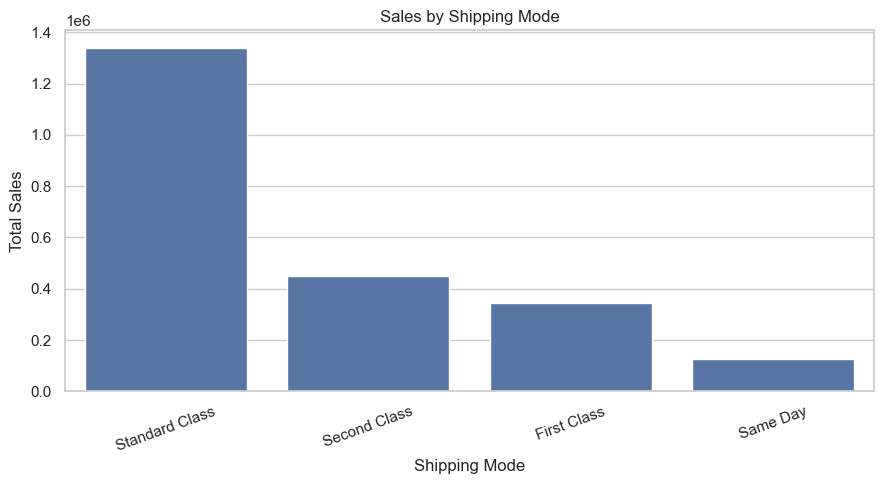

In [50]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=shipping_mode_sales,
    x="Ship Mode",
    y="Sales",
    order=shipping_mode_sales["Ship Mode"]
)

plt.title("Sales by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Total Sales")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


## 25. Shipping Time Analysis

We calculate how many days pass between order placement and shipment.

In [51]:
shipping_summary = df["Shipping Days"].describe()
display(shipping_summary)


count   9,800.00
mean        3.96
std         1.75
min         0.00
25%         3.00
50%         4.00
75%         5.00
max         7.00
Name: Shipping Days, dtype: float64

### Graph: Shipping Days Distribution

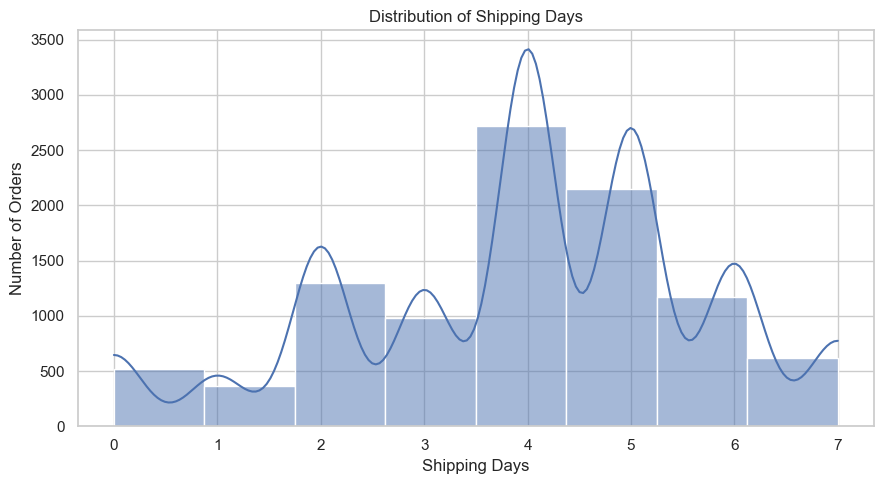

In [52]:
plt.figure(figsize=(9, 5))

sns.histplot(
    df["Shipping Days"],
    bins=8,
    kde=True
)

plt.title("Distribution of Shipping Days")
plt.xlabel("Shipping Days")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()


## 26. Shipping Time by Region

This helps identify geographic operational differences.

In [53]:
shipping_by_region = (
    df.groupby("Region", as_index=False)["Shipping Days"]
      .mean()
      .sort_values("Shipping Days")
)

display(shipping_by_region)


,Region,Shipping Days
1,East,3.91
3,West,3.93
2,South,3.96
0,Central,4.07


### Graph: Average Shipping Time by Region

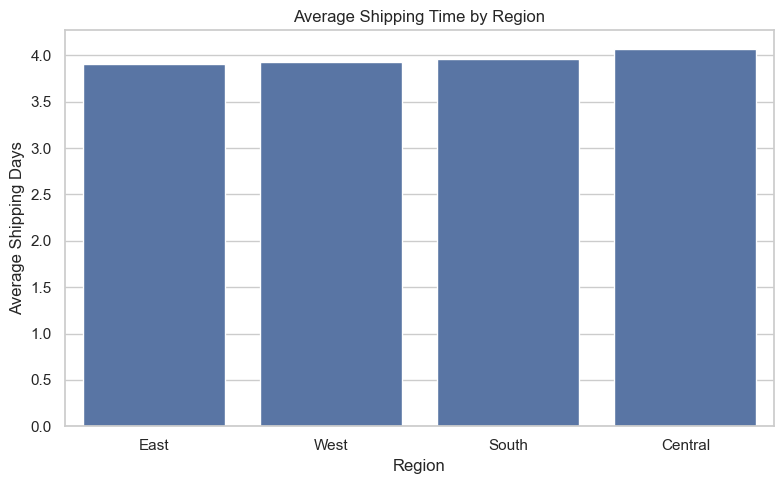

In [55]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=shipping_by_region,
    x="Region",
    y="Shipping Days",
    order=shipping_by_region["Region"]
)

plt.title("Average Shipping Time by Region")
plt.xlabel("Region")
plt.ylabel("Average Shipping Days")
plt.tight_layout()
plt.show()


## 27. Category × Segment Analysis

This identifies which customer segments generate revenue within each category.

In [ ]:
category_segment = pd.pivot_table(
    df,
    values="Sales",
    index="Category",
    columns="Segment",
    aggfunc="sum",
    fill_value=0
)

display(category_segment)


### Graph: Category and Segment Comparison

In [ ]:
category_segment.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Sales by Category and Customer Segment")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 28. Correlation Analysis

We inspect relationships between numerical variables. Correlation indicates association; it does not prove causation.

In [ ]:
numeric_df = df.select_dtypes(include=np.number)

correlation_matrix = numeric_df.corr()

display(correlation_matrix)


### Graph: Correlation Heatmap

In [ ]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Matrix of Numerical Variables")
plt.tight_layout()
plt.show()


## 29. Final Analytical Summary

The following summary is generated dynamically from the analysis results.

In [ ]:
print("=" * 70)
print("FINAL BUSINESS ANALYTICS SUMMARY")
print("=" * 70)

print(f"Total Sales: {total_sales:,.2f}")
print(f"Total Orders: {total_orders:,.0f}")

if pd.notna(total_customers):
    print(f"Total Customers: {total_customers:,.0f}")

if pd.notna(total_products):
    print(f"Total Products: {total_products:,.0f}")

print(f"Average Order Value: {average_order_value:,.2f}")
print(f"Best Sales Year: {int(best_year['Year'])}")
print(f"Best Sales Month: {best_month['Month Name']}")
print(f"Best Sales Quarter: {best_quarter['Quarter']}")
print(f"Top Category: {top_category['Category']}")
print(f"Top Customer Segment: {top_segment['Segment']}")
print(f"Top Region: {top_region['Region']}")
print(f"Top Sub-Category: {top_subcategory['Sub-Category']}")

if "Shipping Days" in df.columns:
    print(f"Average Shipping Time: {df['Shipping Days'].mean():.2f} days")


# 30. Professional Business Recommendations

## Revenue and Growth
- Investigate the drivers of the highest-growth years.
- Analyze the causes of any declining years by region, category, and segment.

## Seasonality
- Prepare inventory, campaigns, and logistics capacity before the strongest sales period.
- Use monthly and quarterly performance as a basis for business planning.

## Products
- Prioritize high-revenue products for inventory availability and promotional activity.
- Review low-performing products for rationalization or repositioning.

## Customers
- Use RFM analysis to prioritize high-value and at-risk customers.
- Create differentiated strategies for Consumer, Corporate, and Home Office customers.

## Regions
- Protect high-performing regions.
- Investigate low-performing regions using customer count, order volume, average order value, and product mix.

## Operations
- Monitor shipping time by region.
- Investigate operational differences where delivery duration is higher.

## Final conclusion

The analysis transforms raw transaction-level sales data into actionable business intelligence by combining data quality assessment, descriptive statistics, KPI analysis, trend analysis, customer analytics, product analytics, regional analysis, and operational analysis.


# End of Project

**Tools used:** Python, Pandas, NumPy, Matplotlib, Seaborn

**Project scope:** Professional Data Analytics and Exploratory Data Analysis only.

The notebook is designed to execute sequentially from data loading through final business recommendations.